# PRML Lab 7 — Neural Networks
**Aryan Tiwari (B20AI056)** · CSL2050 Pattern Recognition & Machine Learning · Winter 2022

In [1]:
import json
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.io import arff
from sklearn.model_selection import train_test_split

warnings.filterwarnings('ignore', message='.*encountered in matmul', category=RuntimeWarning)
SEED = 56
sns.set_theme(style='whitegrid')
results = {}

def savefig(name):
    plt.savefig(f'figures/{name}.png', dpi=150, bbox_inches='tight')

# Question 1 — Abalone age with a two-branch PyTorch network

**Task framing.** The number of rings (age ≈ rings + 1.5 years) ranges from 1 to 29. Treating 29 values as separate classes would give classes with only a handful of samples. So, as is standard for this dataset, the rings are grouped into **three age classes**: young (≤ 8 rings), adult (9–10) and old (≥ 11). These groups are almost balanced (1407 / 1323 / 1447).

**Architecture.** The specification figure isn't in the question PDF that was preserved, only the description: tanh hidden layers, a sigmoid output layer, and **'+' = the outputs of 2 branches are added**. I implement that as two parallel branches fed the same input:
- branch A: Linear(10→h) → tanh → Linear(h→h) → tanh
- branch B: Linear(10→h) → tanh
- **A + B** → Linear(h→3) → sigmoid.

With a sigmoid output, each of the 3 output units is an independent 'is it this class?' score, so the loss is binary cross-entropy against the one-hot target; the prediction is the unit with the highest score.

In [2]:
import torch
import torch.nn as nn
torch.manual_seed(SEED)

COLS = ['Sex', 'Length', 'Diameter', 'Height', 'Whole weight', 'Shucked weight', 'Viscera weight', 'Shell weight', 'Rings']
ab = pd.read_csv('data/abalone.data', header=None, names=COLS)
print(ab.shape, '| missing:', ab.isna().sum().sum(), '| rows with Height = 0:', (ab['Height'] == 0).sum())
ab = ab[ab['Height'] > 0]                                    # a shell cannot have zero height — recording errors
ab['Age group'] = pd.cut(ab['Rings'], [0, 8, 10, 29], labels=[0, 1, 2]).astype(int)
X_ab = pd.get_dummies(ab.drop(columns=['Rings', 'Age group']), columns=['Sex'], dtype=float)   # nominal M/F/I → one-hot
y_ab = ab['Age group'].values
print('classes (young/adult/old):', np.bincount(y_ab), '| features:', X_ab.shape[1])

Xa_tv, Xa_te, ya_tv, ya_te = train_test_split(X_ab.values, y_ab, test_size=0.15, stratify=y_ab, random_state=SEED)
Xa_tr, Xa_va, ya_tr, ya_va = train_test_split(Xa_tv, ya_tv, test_size=0.15 / 0.85, stratify=ya_tv, random_state=SEED)
mu_a, sd_a = Xa_tr.mean(0), Xa_tr.std(0)
norm = lambda A: torch.tensor((A - mu_a) / sd_a, dtype=torch.float32)
Ta_tr, Ta_va, Ta_te = norm(Xa_tr), norm(Xa_va), norm(Xa_te)
print('train', len(ya_tr), '| val', len(ya_va), '| test', len(ya_te))

(4177, 9) | missing: 0 | rows with Height = 0: 2
classes (young/adult/old): [1405 1323 1447] | features: 10
train 2921 | val 627 | test 627


In [3]:
class TwoBranchNet(nn.Module):
    def __init__(self, n_in, hidden, n_out):
        super().__init__()
        self.branch_a = nn.Sequential(nn.Linear(n_in, hidden), nn.Tanh(), nn.Linear(hidden, hidden), nn.Tanh())
        self.branch_b = nn.Sequential(nn.Linear(n_in, hidden), nn.Tanh())
        self.out = nn.Sequential(nn.Linear(hidden, n_out), nn.Sigmoid())

    def forward(self, x):
        return self.out(self.branch_a(x) + self.branch_b(x))

def train_two_branch(hidden, epochs=300, lr=1e-2, seed=SEED):
    torch.manual_seed(seed)
    net = TwoBranchNet(Ta_tr.shape[1], hidden, 3)
    opt = torch.optim.Adam(net.parameters(), lr=lr)
    loss_fn = nn.BCELoss()
    Y_tr = nn.functional.one_hot(torch.tensor(ya_tr), 3).float()
    hist, best = [], (np.inf, None)
    for ep in range(epochs):
        net.train(); opt.zero_grad()
        loss = loss_fn(net(Ta_tr), Y_tr); loss.backward(); opt.step()
        net.eval()
        with torch.no_grad():
            va_loss = loss_fn(net(Ta_va), nn.functional.one_hot(torch.tensor(ya_va), 3).float()).item()
            va_acc = (net(Ta_va).argmax(1).numpy() == ya_va).mean()
        hist.append((loss.item(), va_loss, va_acc))
        if va_loss < best[0]:
            best = (va_loss, {k: v.clone() for k, v in net.state_dict().items()})
    net.load_state_dict(best[1])                      # keep the epoch with the lowest validation loss
    return net, np.array(hist)

sizes = {}
for h in [4, 8, 16, 32, 64]:
    net, hist = train_two_branch(h)
    with torch.no_grad():
        sizes[h] = (net(Ta_va).argmax(1).numpy() == ya_va).mean()
best_h = max(sizes, key=sizes.get)
results['q1_hidden_val_acc'] = {str(k): float(v) for k, v in sizes.items()}
print('validation accuracy by hidden size:', {k: round(v, 4) for k, v in sizes.items()}, '→ h =', best_h)

validation accuracy by hidden size: {4: np.float64(0.6539), 8: np.float64(0.6794), 16: np.float64(0.681), 32: np.float64(0.6699), 64: np.float64(0.6683)} → h = 16


TwoBranchNet(
  (branch_a): Sequential(
    (0): Linear(in_features=10, out_features=16, bias=True)
    (1): Tanh()
    (2): Linear(in_features=16, out_features=16, bias=True)
    (3): Tanh()
  )
  (branch_b): Sequential(
    (0): Linear(in_features=10, out_features=16, bias=True)
    (1): Tanh()
  )
  (out): Sequential(
    (0): Linear(in_features=16, out_features=3, bias=True)
    (1): Sigmoid()
  )
)
parameters: 675 | test accuracy: 0.6794
predicted  adult  old  young
true                        
adult        106   58     35
old           43  165      9
young         44   12    155


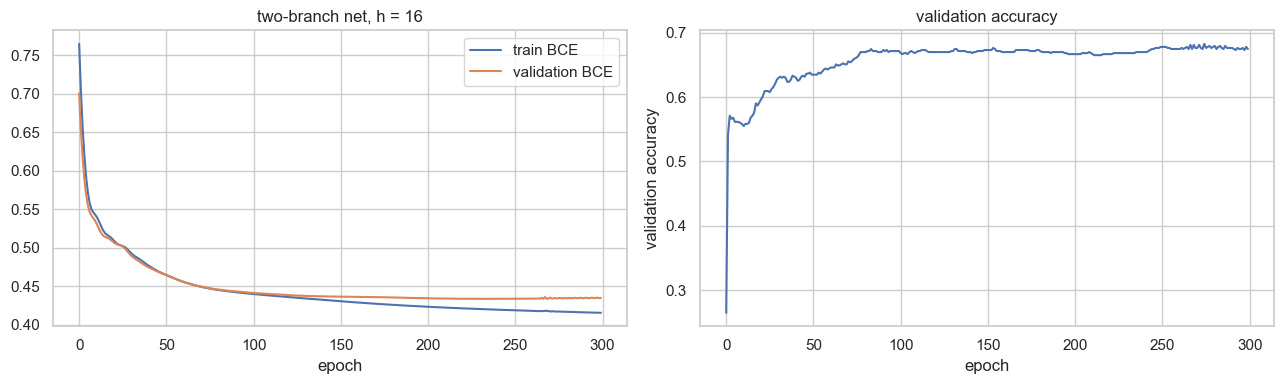

In [4]:
net, hist = train_two_branch(best_h)
with torch.no_grad():
    pred_te = net(Ta_te).argmax(1).numpy()
acc_te = (pred_te == ya_te).mean()
cm = pd.crosstab(pd.Series(ya_te, name='true').map({0: 'young', 1: 'adult', 2: 'old'}),
                 pd.Series(pred_te, name='predicted').map({0: 'young', 1: 'adult', 2: 'old'}))
results['q1'] = {'hidden': int(best_h), 'test_acc': float(acc_te), 'params': int(sum(p.numel() for p in net.parameters())),
                 'per_class': {n: float((pred_te[ya_te == k] == k).mean()) for k, n in enumerate(['young', 'adult', 'old'])}}
print(net)
print(f'parameters: {results["q1"]["params"]} | test accuracy: {acc_te:.4f}')
print(cm)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(hist[:, 0], label='train BCE'); ax[0].plot(hist[:, 1], label='validation BCE'); ax[0].set_xlabel('epoch'); ax[0].legend(); ax[0].set_title(f'two-branch net, h = {best_h}')
ax[1].plot(hist[:, 2]); ax[1].set_xlabel('epoch'); ax[1].set_ylabel('validation accuracy'); ax[1].set_title('validation accuracy')
plt.tight_layout(); savefig('q1_training'); plt.show()

# Question 2 — Dry Bean classification with an MLP written from scratch

### a. Pre-processing, visualisation and stratified splits

In [5]:
raw, _ = arff.loadarff('data/DryBeanDataset/Dry_Bean_Dataset.arff')
beans = pd.DataFrame(raw)
beans['Class'] = beans['Class'].str.decode('utf-8')
FEATS = ['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'Eccentricity', 'roundness', 'AspectRation', 'ConvexArea']
print(beans.shape, '| missing:', beans.isna().sum().sum(), '| duplicates:', beans.duplicated().sum())
beans = beans.drop_duplicates()[FEATS + ['Class']]
CLASSES = sorted(beans['Class'].unique())
print(beans['Class'].value_counts().to_dict())

(13611, 17) | missing: 0 | duplicates: 68
{'DERMASON': 3546, 'SIRA': 2636, 'SEKER': 2027, 'HOROZ': 1860, 'CALI': 1630, 'BARBUNYA': 1322, 'BOMBAY': 522}


The question lists "area, perimeter, axes lengths, eccentricity, roundness, aspect ratio and convex area". 'Axes lengths' means two columns (major and minor), so 8 columns are used. The 68 exact duplicate rows are dropped. The classes are imbalanced (Bombay is 4% of the data, Dermason 26%), so every split is **stratified**: 70 / 15 / 15 train / validation / test, each keeping the class proportions.

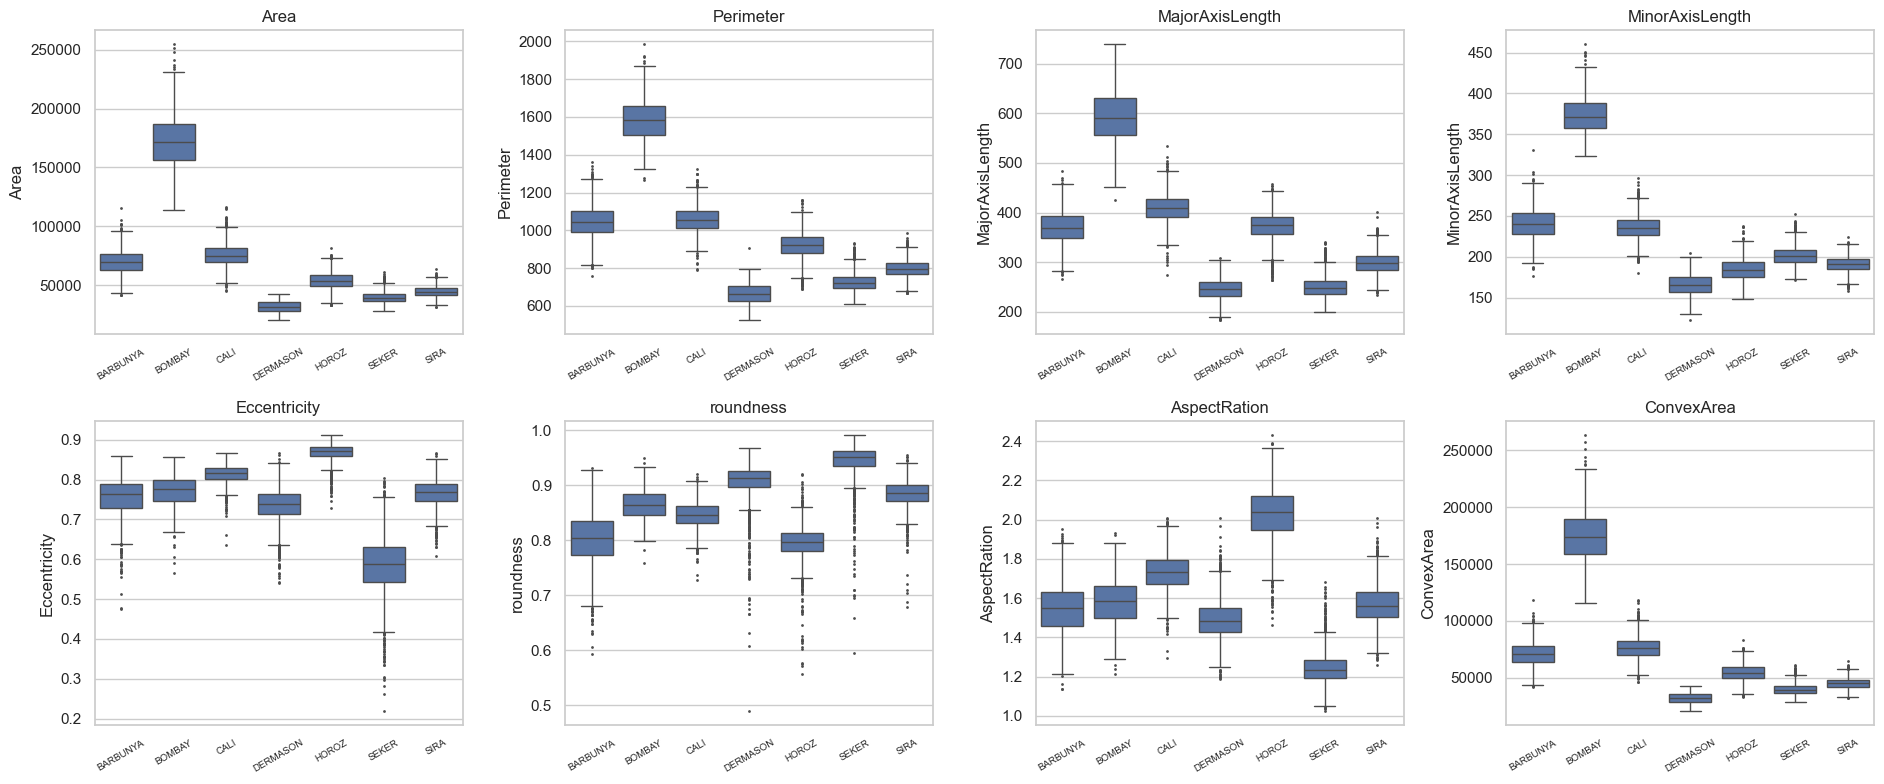

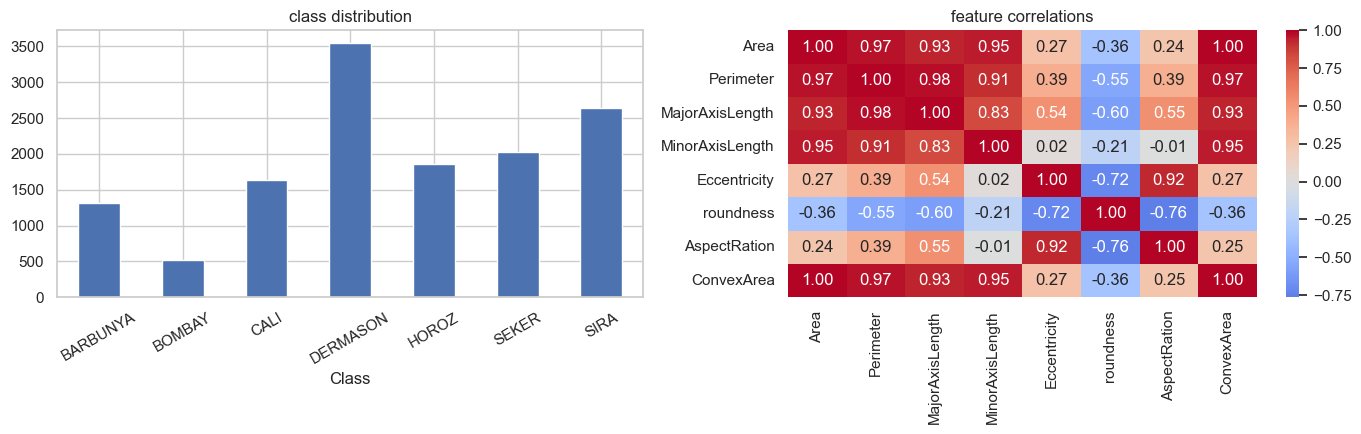

In [6]:
fig, ax = plt.subplots(2, 4, figsize=(19, 8))
for a, f in zip(ax.flat, FEATS):
    sns.boxplot(data=beans, x='Class', y=f, ax=a, order=CLASSES, fliersize=1)
    a.set_title(f); a.tick_params(axis='x', labelsize=7, rotation=30); a.set_xlabel('')
plt.tight_layout(); savefig('q2_eda'); plt.show()

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
beans['Class'].value_counts().reindex(CLASSES).plot.bar(ax=ax[0], rot=30); ax[0].set_title('class distribution')
sns.heatmap(beans[FEATS].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax[1]); ax[1].set_title('feature correlations')
plt.tight_layout(); savefig('q2_eda_2'); plt.show()

In [7]:
Xb = beans[FEATS].values
yb = beans['Class'].map({c: i for i, c in enumerate(CLASSES)}).values
Xb_tv, Xb_te, yb_tv, yb_te = train_test_split(Xb, yb, test_size=0.15, stratify=yb, random_state=SEED)
Xb_tr, Xb_va, yb_tr, yb_va = train_test_split(Xb_tv, yb_tv, test_size=0.15 / 0.85, stratify=yb_tv, random_state=SEED)
mu_b, sd_b = Xb_tr.mean(0), Xb_tr.std(0)
Xb_tr, Xb_va, Xb_te = [(A - mu_b) / sd_b for A in (Xb_tr, Xb_va, Xb_te)]
print('train', Xb_tr.shape, '| val', Xb_va.shape, '| test', Xb_te.shape)
print('class shares  train', np.round(np.bincount(yb_tr) / len(yb_tr), 3), '\n              test ', np.round(np.bincount(yb_te) / len(yb_te), 3))

train (9479, 8) | val (2032, 8) | test (2032, 8)
class shares  train [0.098 0.039 0.12  0.262 0.137 0.15  0.195] 
              test  [0.097 0.038 0.121 0.262 0.137 0.15  0.195]


### b. The MLP
- **i.** Activation functions and their derivatives, written by hand.
- **ii.** The forward pass stores every pre-activation *z* and activation *a*. The output layer is softmax.
- **iii.** Backpropagation: with softmax + cross-entropy, the output error is simply $\hat y - y$. Each earlier layer gets $\delta^{l} = (\delta^{l+1}W^{l+1\top})\odot f'(z^{l})$.
- **iv.** Stochastic gradient descent: weights are updated after every mini-batch of 32 shuffled samples (`batch_size=1` gives pure per-sample SGD).
- **v.** `predict` takes the argmax of the output, and `accuracy` compares it with the labels.
- **f.** `save` and `load` write and read all weights and biases in a NumPy `.npz` file.

In [8]:
ACTIVATIONS = {
    'sigmoid':    (lambda z: 1 / (1 + np.exp(-np.clip(z, -500, 500))),  lambda z, a: a * (1 - a)),
    'tanh':       (lambda z: np.tanh(z),                                lambda z, a: 1 - a ** 2),
    'relu':       (lambda z: np.maximum(0, z),                          lambda z, a: (z > 0).astype(float)),
    'leaky_relu': (lambda z: np.where(z > 0, z, 0.01 * z),              lambda z, a: np.where(z > 0, 1.0, 0.01)),
}

def softmax(z):
    z = z - z.max(1, keepdims=True)
    e = np.exp(z)
    return e / e.sum(1, keepdims=True)

class MLP:
    def __init__(self, sizes, activation='relu', init='random', const=0.5, seed=SEED):
        self.sizes, self.activation = sizes, activation
        self.f, self.df = ACTIVATIONS[activation]
        rng = np.random.default_rng(seed)
        self.W, self.b = [], []
        for n_in, n_out in zip(sizes[:-1], sizes[1:]):
            if init == 'random':        # He for ReLU-type, Xavier/Glorot for saturating activations
                scale = np.sqrt(2 / n_in) if 'relu' in activation else np.sqrt(1 / n_in)
                W = rng.normal(0, scale, (n_in, n_out))
            elif init == 'zero':
                W = np.zeros((n_in, n_out))
            elif init == 'constant':
                W = np.full((n_in, n_out), const)
            self.W.append(W); self.b.append(np.zeros(n_out))

    def forward(self, X):
        self.zs, self.acts = [], [X]
        a = X
        for l, (W, b) in enumerate(zip(self.W, self.b)):
            z = a @ W + b
            a = softmax(z) if l == len(self.W) - 1 else self.f(z)
            self.zs.append(z); self.acts.append(a)
        return a

    def backward(self, Y):
        grads_W, grads_b = [None] * len(self.W), [None] * len(self.W)
        delta = (self.acts[-1] - Y) / len(Y)                          # softmax + cross-entropy
        for l in range(len(self.W) - 1, -1, -1):
            grads_W[l] = self.acts[l].T @ delta
            grads_b[l] = delta.sum(0)
            if l:
                delta = (delta @ self.W[l].T) * self.df(self.zs[l - 1], self.acts[l])
        return grads_W, grads_b

    def fit(self, X, y, X_val=None, y_val=None, epochs=40, lr=0.05, batch_size=32, seed=SEED):
        rng = np.random.default_rng(seed)
        Y = np.eye(self.sizes[-1])[y]
        self.history = []
        for ep in range(epochs):
            idx = rng.permutation(len(X))
            for start in range(0, len(X), batch_size):
                bi = idx[start:start + batch_size]
                self.forward(X[bi])
                gW, gb = self.backward(Y[bi])
                for l in range(len(self.W)):
                    self.W[l] -= lr * gW[l]; self.b[l] -= lr * gb[l]
            row = {'epoch': ep + 1, 'train loss': self.loss(X, y), 'train acc': self.accuracy(X, y)}
            if X_val is not None:
                row.update({'val loss': self.loss(X_val, y_val), 'val acc': self.accuracy(X_val, y_val)})
            self.history.append(row)
        self.history = pd.DataFrame(self.history)
        return self

    def loss(self, X, y):
        p = self.forward(X)
        return float(-np.mean(np.log(p[np.arange(len(y)), y] + 1e-12)))

    def predict(self, X):
        return self.forward(X).argmax(1)

    def accuracy(self, X, y):
        return float(np.mean(self.predict(X) == y))

    def save(self, path):
        np.savez(path, sizes=np.array(self.sizes), activation=self.activation,
                 **{f'W{l}': W for l, W in enumerate(self.W)}, **{f'b{l}': b for l, b in enumerate(self.b)})

    @classmethod
    def load(cls, path):
        d = np.load(path)
        m = cls(d['sizes'].tolist(), activation=str(d['activation']))
        m.W = [d[f'W{l}'] for l in range(len(m.sizes) - 1)]
        m.b = [d[f'b{l}'] for l in range(len(m.sizes) - 1)]
        return m

In [9]:
# gradient check on a tiny network: analytic backprop vs. central finite differences
gc = MLP([8, 5, 7], activation='tanh', seed=1)
Xg, yg = Xb_tr[:6], yb_tr[:6]
gc.forward(Xg); gW, _ = gc.backward(np.eye(7)[yg])
num = np.zeros_like(gc.W[0]); eps = 1e-5
for i in range(gc.W[0].shape[0]):
    for j in range(gc.W[0].shape[1]):
        gc.W[0][i, j] += eps; lp = gc.loss(Xg, yg)
        gc.W[0][i, j] -= 2 * eps; lm = gc.loss(Xg, yg)
        gc.W[0][i, j] += eps; num[i, j] = (lp - lm) / (2 * eps)
rel = np.abs(num - gW[0]).max() / np.abs(num).max()
results['q2_gradcheck_rel_err'] = float(rel)
print(f'gradient check, relative error = {rel:.2e}')

gradient check, relative error = 2.18e-10


8-32-32-7 ReLU MLP: test accuracy 0.9129  (1.1s)


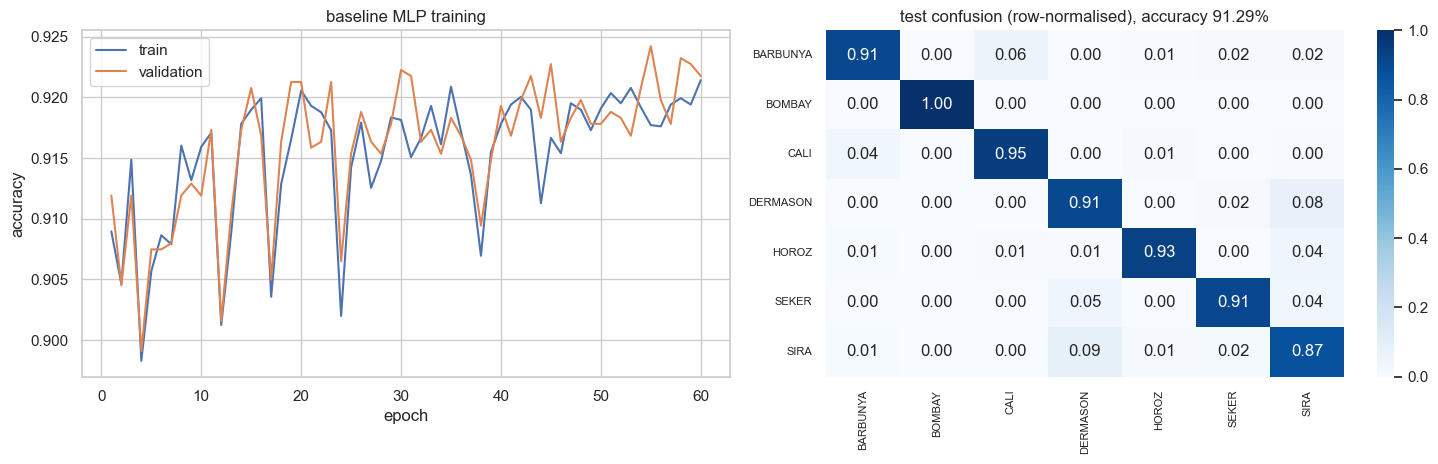

BARBUNYA    0.909
BOMBAY      1.000
CALI        0.947
DERMASON    0.908
HOROZ       0.932
SEKER       0.911
SIRA        0.871
dtype: float64

In [10]:
ARCH = [8, 32, 32, 7]
t0 = time.time()
base = MLP(ARCH, 'relu').fit(Xb_tr, yb_tr, Xb_va, yb_va, epochs=60)
base_test = base.accuracy(Xb_te, yb_te)
pred_b = base.predict(Xb_te)
results['q2_base'] = {'arch': ARCH, 'test_acc': base_test, 'val_acc': float(base.history['val acc'].iloc[-1]),
                      'per_class': {c: float((pred_b[yb_te == k] == k).mean()) for k, c in enumerate(CLASSES)},
                      'train_seconds': round(time.time() - t0, 1)}
print(f'8-32-32-7 ReLU MLP: test accuracy {base_test:.4f}  ({time.time() - t0:.1f}s)')
cm = np.zeros((7, 7), int); np.add.at(cm, (yb_te, pred_b), 1)
fig, ax = plt.subplots(1, 2, figsize=(15, 4.8))
ax[0].plot(base.history['epoch'], base.history['train acc'], label='train'); ax[0].plot(base.history['epoch'], base.history['val acc'], label='validation')
ax[0].set_xlabel('epoch'); ax[0].set_ylabel('accuracy'); ax[0].legend(); ax[0].set_title('baseline MLP training')
sns.heatmap(cm / cm.sum(1, keepdims=True), annot=True, fmt='.2f', cmap='Blues', xticklabels=CLASSES, yticklabels=CLASSES, ax=ax[1])
ax[1].set_title(f'test confusion (row-normalised), accuracy {base_test:.2%}'); ax[1].tick_params(labelsize=8)
plt.tight_layout(); savefig('q2_baseline'); plt.show()
pd.Series(results['q2_base']['per_class']).round(3)

### c. Activation functions

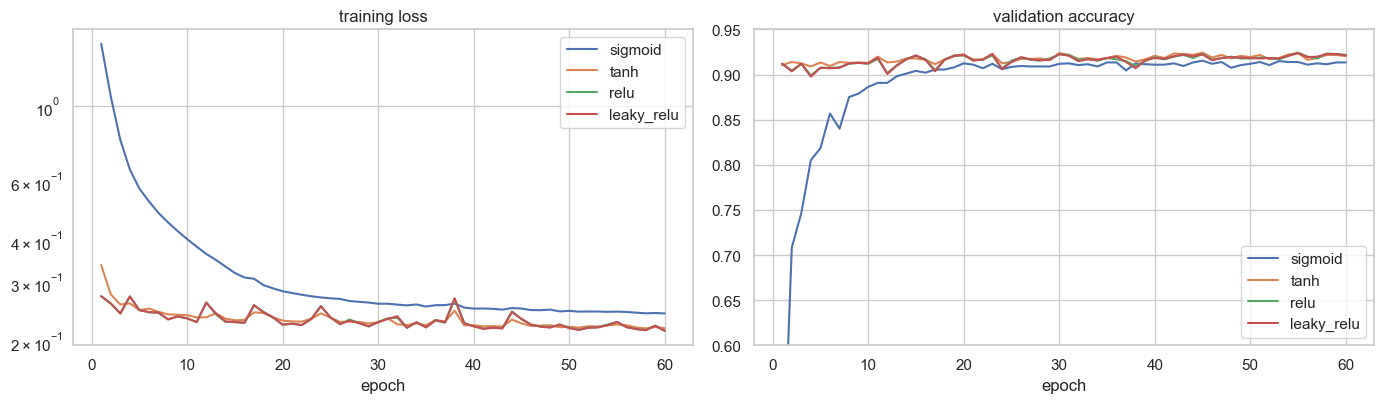

,train acc,val acc,test acc,epoch to reach 90% val
activation,,,,
sigmoid,0.9134,0.9134,0.9129,14
tanh,0.9209,0.9203,0.9139,1
relu,0.9214,0.9218,0.9129,1
leaky_relu,0.9210,0.9213,0.9124,1


In [11]:
act_hist, act_rows = {}, []
for act in ['sigmoid', 'tanh', 'relu', 'leaky_relu']:
    m = MLP(ARCH, act).fit(Xb_tr, yb_tr, Xb_va, yb_va, epochs=60)
    act_hist[act] = m.history
    act_rows.append({'activation': act, 'train acc': m.accuracy(Xb_tr, yb_tr), 'val acc': m.accuracy(Xb_va, yb_va),
                     'test acc': m.accuracy(Xb_te, yb_te), 'epoch to reach 90% val': int((m.history['val acc'] >= 0.9).idxmax() + 1) if (m.history['val acc'] >= 0.9).any() else None})
act_df = pd.DataFrame(act_rows).set_index('activation')
results['q2_activations'] = act_df.round(4).to_dict('index')
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
for act, h in act_hist.items():
    ax[0].plot(h['epoch'], h['train loss'], label=act); ax[1].plot(h['epoch'], h['val acc'], label=act)
ax[0].set_yscale('log'); ax[0].set_title('training loss'); ax[1].set_title('validation accuracy'); ax[1].set_ylim(0.6, 0.95)
for a in ax: a.set_xlabel('epoch'); a.legend()
plt.tight_layout(); savefig('q2_activations'); plt.show()
act_df.round(4)

### d. Weight initialisation: random vs zero vs constant

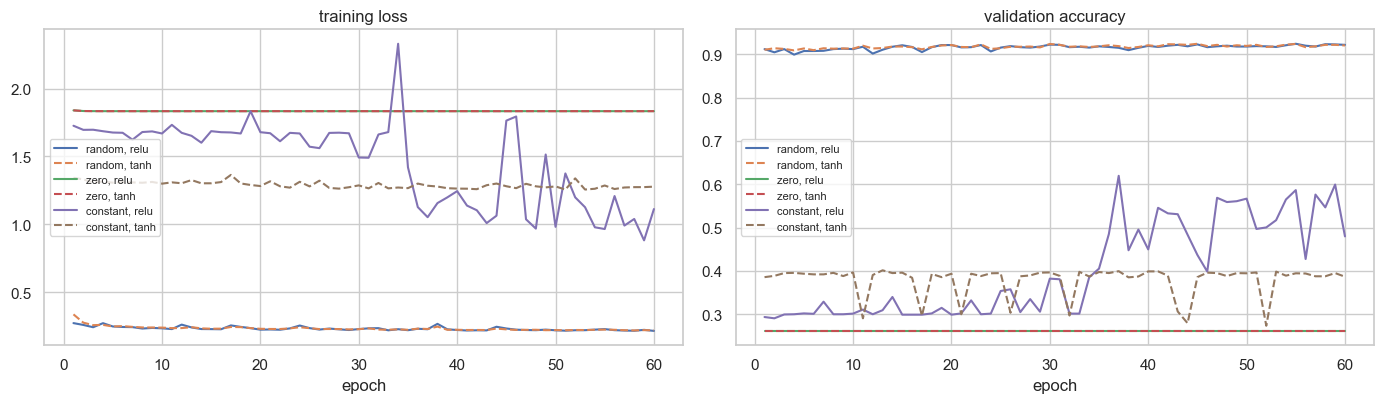

test acc  distinct hidden-unit behaviours (layer 1)
init     activation                                                     
random   relu          0.9129                                         32
         tanh          0.9139                                         32
zero     relu          0.2618                                          1
         tanh          0.2618                                          1
constant relu          0.4847                                          1
         tanh          0.3883                                          1

In [12]:
init_hist, init_rows = {}, []
for init in ['random', 'zero', 'constant']:
    for act in ['relu', 'tanh']:
        m = MLP(ARCH, act, init=init).fit(Xb_tr, yb_tr, Xb_va, yb_va, epochs=60)
        init_hist[(init, act)] = m.history
        h1 = m.forward(Xb_va) is not None and m.acts[1]
        distinct_units = len(np.unique(np.round(h1.std(0), 6)))
        init_rows.append({'init': init, 'activation': act, 'test acc': m.accuracy(Xb_te, yb_te),
                          'distinct hidden-unit behaviours (layer 1)': distinct_units})
init_df = pd.DataFrame(init_rows).set_index(['init', 'activation'])
results['q2_init'] = {f'{i} | {a}': v for (i, a), v in init_df.round(4).to_dict('index').items()}
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
for (init, act), h in init_hist.items():
    ls = '-' if act == 'relu' else '--'
    ax[0].plot(h['epoch'], h['train loss'], ls, label=f'{init}, {act}'); ax[1].plot(h['epoch'], h['val acc'], ls, label=f'{init}, {act}')
ax[0].set_title('training loss'); ax[1].set_title('validation accuracy')
for a in ax: a.set_xlabel('epoch'); a.legend(fontsize=8)
plt.tight_layout(); savefig('q2_init'); plt.show()
init_df.round(4)

### e. Number of hidden nodes

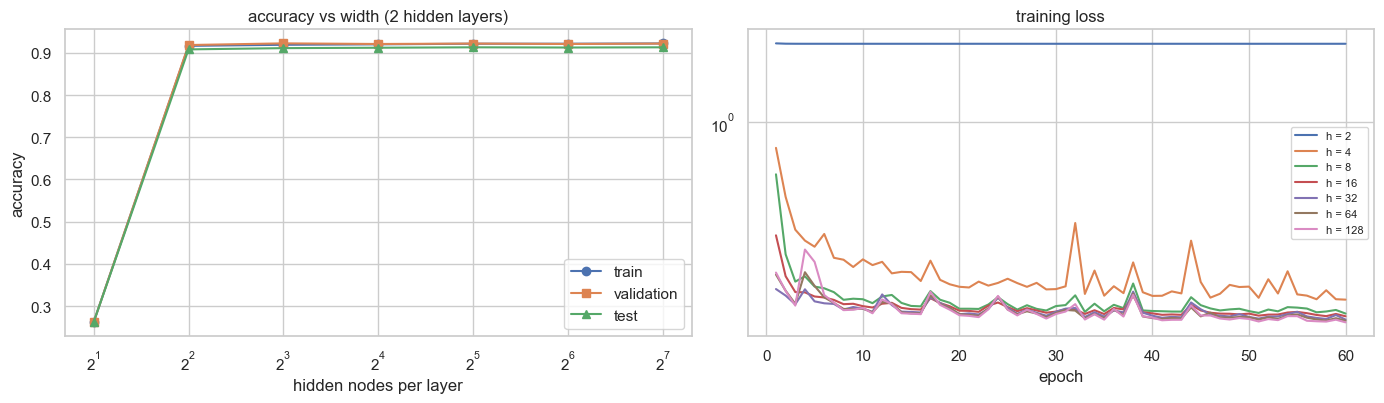

,parameters,train acc,val acc,test acc,seconds
hidden nodes,,,,,
2,45,0.2618,0.2618,0.2618,0.5
4,91,0.9163,0.9183,0.9080,0.5
8,207,0.9189,0.9222,0.9109,0.7
16,535,0.9199,0.9208,0.9119,0.9
32,1575,0.9214,0.9218,0.9129,1.1
64,5191,0.9214,0.9208,0.9124,1.3
128,18567,0.9220,0.9218,0.9129,1.9


In [13]:
hid_rows, hid_hist = [], {}
for h in [2, 4, 8, 16, 32, 64, 128]:
    t0 = time.time()
    m = MLP([8, h, h, 7], 'relu').fit(Xb_tr, yb_tr, Xb_va, yb_va, epochs=60)
    hid_hist[h] = m.history
    hid_rows.append({'hidden nodes': h, 'parameters': sum(W.size + b.size for W, b in zip(m.W, m.b)),
                     'train acc': m.accuracy(Xb_tr, yb_tr), 'val acc': m.accuracy(Xb_va, yb_va), 'test acc': m.accuracy(Xb_te, yb_te),
                     'seconds': round(time.time() - t0, 1)})
hid_df = pd.DataFrame(hid_rows).set_index('hidden nodes')
results['q2_hidden'] = hid_df.round(4).to_dict('index')
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
ax[0].plot(hid_df.index, hid_df['train acc'], 'o-', label='train'); ax[0].plot(hid_df.index, hid_df['val acc'], 's-', label='validation')
ax[0].plot(hid_df.index, hid_df['test acc'], '^-', label='test'); ax[0].set_xscale('log', base=2); ax[0].set_xlabel('hidden nodes per layer'); ax[0].set_ylabel('accuracy'); ax[0].legend(); ax[0].set_title('accuracy vs width (2 hidden layers)')
for h, hh in hid_hist.items():
    ax[1].plot(hh['epoch'], hh['train loss'], label=f'h = {h}')
ax[1].set_yscale('log'); ax[1].set_xlabel('epoch'); ax[1].set_title('training loss'); ax[1].legend(fontsize=8)
plt.tight_layout(); savefig('q2_hidden'); plt.show()
hid_df.round(4)

### f. Saving and loading weights

In [14]:
base.save('mlp_weights.npz')
restored = MLP.load('mlp_weights.npz')
same = np.array_equal(restored.predict(Xb_te), base.predict(Xb_te))
results['q2_save_load_identical'] = bool(same)
print('restored model gives identical predictions:', same, '| restored test accuracy:', restored.accuracy(Xb_te, yb_te))

with open('results.json', 'w') as f:
    json.dump(results, f, indent=2, default=float)

restored model gives identical predictions: True | restored test accuracy: 0.9128937007874016
